In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# pandas exibir todas as colunas
pd.set_option('display.max_columns', None)

In [4]:
papel = 'PETR3.SA'

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base = pp.buscar_dados_papeis_adicionais(df_base, ['PETR4.SA'])
df_base.tail(10)

[PETR3.SA] Cache existente cobre de 2020-01-02 a 2025-06-16.
[PETR3.SA] Cache cobre período solicitado (2022-12-29 a 2025-06-16).
[PETR3.SA] Retornando 613 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20211229_20250617.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-16.
[^BVSP] Cache cobre período solicitado (2022-12-29 a 2025-06-16).
[^BVSP] Retornando 613 linhas para o período solicitado.
[PETR4.SA] Cache existente cobre de 2020-01-02 a 2025-06-16.
[PETR4.SA] Cache cobre período solicitado (2022-12-29 a 2025-06-16).
[PETR4.SA] Retornando 613 linhas para o período solicitado.


,data,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov,adc_open_PETR4,adc_high_PETR4,adc_low_PETR4,adc_close_PETR4,adc_volume_PETR4,adc_pct_change_PETR4,adc_vol_PETR4,adc_rsi_PETR4,adc_macd_PETR4,adc_macd_signal_PETR4,adc_macd_hist_PETR4,adc_tr_PETR4,adc_atr_PETR4,adc_atr_pct_PETR4,adc_tr_pct_PETR4,adc_mm5_PETR4,adc_mm20_PETR4
603,2025-06-03,31.299999,32.340000,31.100000,32.310001,12989200,0.006516,0.008479,44.278553,-0.262065,-0.279580,0.017515,1.240000,0.765279,0.023686,0.038378,32.263252,32.661704,14.75,0.26,5.6694,136787.00000,137672.0000,136175.00000,137546.000000,9696700,29.879999,30.299999,29.389999,30.180000,59828700,0.000304,0.007199,44.490643,-0.172330,-0.176881,0.004551,0.910000,0.630436,0.020889,0.030152,30.236736,30.512024
604,2025-06-04,32.340000,32.599998,31.370001,31.370001,6208700,-0.029093,0.011855,35.619627,-0.329669,-0.289598,-0.040071,1.229998,0.798473,0.025453,0.039209,32.043179,32.650932,14.75,0.26,5.6332,137547.00000,138797.0000,136695.00000,137002.000000,10199100,30.240000,30.450001,29.270000,29.350000,41952900,-0.027502,0.010361,35.928987,-0.240956,-0.189696,-0.051260,1.180000,0.669691,0.022817,0.040204,30.004617,30.509327
605,2025-06-05,31.510000,31.760000,31.150000,31.200001,7227900,-0.005419,0.011487,34.312759,-0.392439,-0.310166,-0.082273,0.610001,0.785011,0.025161,0.019551,31.796885,32.604918,14.75,0.26,5.5969,137003.00000,137451.0000,136031.00000,136236.000000,9484500,29.500000,29.639999,29.209999,29.360001,23774000,0.000341,0.010022,36.088569,-0.291179,-0.209993,-0.081186,0.430000,0.652570,0.022226,0.014646,29.811386,30.486744
606,2025-06-06,31.299999,31.850000,31.219999,31.570000,9612200,0.011859,0.012468,39.514292,-0.407630,-0.329659,-0.077972,0.650000,0.775367,0.024560,0.020589,31.710167,32.569138,14.75,0.26,5.5947,136236.00000,136890.0000,135601.00000,136102.000000,9119300,29.450001,29.830000,29.360001,29.670000,28069300,0.010559,0.010860,40.994807,-0.302479,-0.228490,-0.073989,0.469999,0.639529,0.021555,0.015841,29.746167,30.469954
607,2025-06-09,31.100000,31.480000,30.840000,31.240000,9477200,-0.010453,0.012614,36.721319,-0.441212,-0.351969,-0.089242,0.730000,0.772127,0.024716,0.023367,31.538000,32.473098,14.75,0.26,5.5760,136102.00000,136106.0000,134119.00000,135699.000000,7763800,29.219999,29.469999,28.860001,29.170000,43834800,-0.016852,0.011759,36.171643,-0.347772,-0.252347,-0.095426,0.809999,0.651706,0.022342,0.027768,29.546000,30.392246
608,2025-06-10,31.510000,32.500000,31.430000,32.380001,12033700,0.036492,0.017700,49.896503,-0.371554,-0.355886,-0.015667,1.260000,0.806975,0.024922,0.038913,31.552000,32.424332,14.75,0.26,5.5557,135716.00000,137369.0000,135716.00000,136436.000000,8186500,29.410000,30.219999,29.350000,30.049999,46241800,0.030168,0.015746,47.809906,-0.309095,-0.263696,-0.045399,1.049999,0.680155,0.022634,0.034942,29.520000,30.335240
609,2025-06-11,32.419998,33.500000,32.419998,33.330002,15665100,0.029339,0.019629,57.784619,-0.236960,-0.332101,0.095141,1.119999,0.829334,0.024882,0.033603,31.944001,32.433764,14.75,0.26,5.5390,136443.00000,137531.0000,135628.00000,137128.000000,8767100,30.299999,31.160000,30.299999,31.049999,52432400,0.033278,0.019211,57.331046,-0.195499,-0.250057,0.054558,1.110001,0.710858,0.022894,0.035749,29.860000,30.338912
610,2025-06-12,32.910000,34.360001,32.900002,34.250000,10820700,0.027603,0.021041,63.738483,-0.055419,-0.276765,0.221345,1.459999,0.874381,0.025529,0.042628,32.554000,32.483848,14.75,0.26,5.5388,137127.00000,137931.0000,136175.00000,137800.000000,7124600,30.799999,31.910000,30.730000,31.750000,51729500,0.022544,0.020005,62.489681,-0.048430,-0.209731,0.161302,1.180000,0.744369,0.023445,0.037165,30.338000,30.379526
611,2025-06-13,35.610001,35.779999,34.820000,34.980000,21208800,0.021314,0.020424,67.638585,0.145679,-0.192276,0.337955,1.529999,0.921211,0.026335,0.043739,33.236000,32.572376,14.75,0.26,5.5652,13780

## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
603,0.765279,0.023686,1.240000,0.038378
604,0.798473,0.025453,1.229998,0.039209
605,0.785011,0.025161,0.610001,0.019551
606,0.775367,0.024560,0.650000,0.020589
607,0.772127,0.024716,0.730000,0.023367
608,0.806975,0.024922,1.260000,0.038913
609,0.829334,0.024882,1.119999,0.033603
610,0.874381,0.025529,1.459999,0.042628
611,0.921211,0.026335,1.529999,0.043739
612,0.922553,0.026336,0.939999,0.026834


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.63%
Valorização sugerida: 3.95%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [9]:
valorizacao = 0.04
DIAS_FUTURO = 5  # dias futuros para buscar a valorização

In [10]:
df = pp.calcular_target(df_base, x_pct=valorizacao, dias_futuro=DIAS_FUTURO)

In [11]:
df['Target'].value_counts(normalize=True)

Target
0.0    0.730263
1.0    0.269737
Name: proportion, dtype: float64

In [13]:
# Preparar X e y para treino
DIAS_JANELA_X = 15  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

Papéis adicionais detectados para agregação: ['PETR4']
INFO: 20 linha(s) serão removidas de X e y devido a NaNs (dropna='linhas').


In [14]:
X_filtrado_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_filtrado_validacao = X_validacao[X_filtrado_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_filtrado_train.shape[1]}")

Features removidas por alta correlação: ['atr_pct_ultimo', 'close_vs_mm20', 'macd_hist_ultimo', 'close_max', 'macd_ultimo_norm_atr', 'macd_hist_ultimo_norm_atr', 'tr_std_norm_atr', 'macd_signal_ultimo_norm_atr', 'adc_ret_acum_PETR4', 'macd_signal_std', 'rsi_mean', 'adc_close_trend_PETR4', 'close_min', 'adc_rsi_ultimo_PETR4', 'ibov_amplitude', 'close_std', 'close_std_norm_atr', 'retorno_acumulado']
Colunas restantes após filtragem: 56


In [15]:
modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
modelo.fit(X_filtrado_train.values, y_train.values)

tr.comparar_auc_conjuntos(modelo, X_filtrado_train, y_train, X_filtrado_validacao, y_validacao)


AUC no treino: 0.623
AUC na validação: 0.473
Diferença AUC (Treino - Validação): 0.150
PROVÁVEL OVERFITTING
PR AUC no treino: 0.498
PR AUC na validação: 0.324
Diferença PR AUC (Treino - Validação): 0.174


(np.float64(0.6225812045606964),
 np.float64(0.4730448926557225),
 np.float64(0.1495363119049739),
 np.float64(0.4979297607952544),
 np.float64(0.32364020896660156))

Avaliar e logar modelo
MLflow Run ID: aa9f74800e8441bba1c7444b8db95507 para PETR3.SA_15dias_x_0.04val_5dias_alvo
AUC no treino: 0.550
AUC na validação: 0.552

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.623
  Precisão média (em 399 janelas com previsão positiva): 0.352
  Recall médio: 0.549

Calibrando thresholds para precisão mínima de 0.70...
Nenhum threshold atendeu à precisão mínima de 0.70. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.147
Recall médio: 0.543
Sinais de compra presentes na vallidação: 17.0
Sinais de compra previstos na validação: 60
Modelo PETR3.SA_15dias_x_0.04val_5dias_alvo salvo na run aa9f74800e8441bba1c7444b8db95507


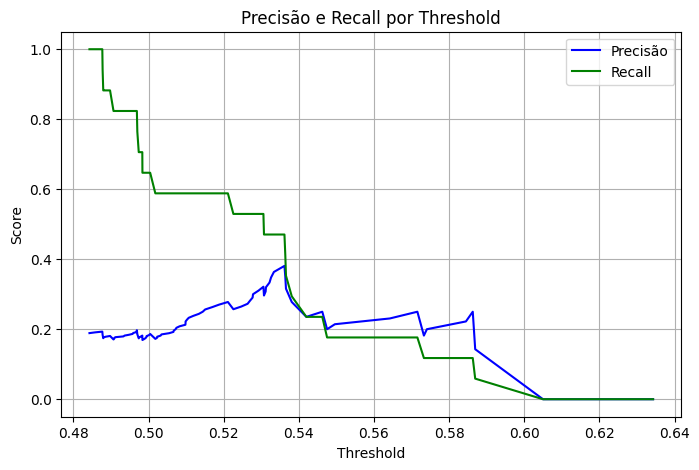

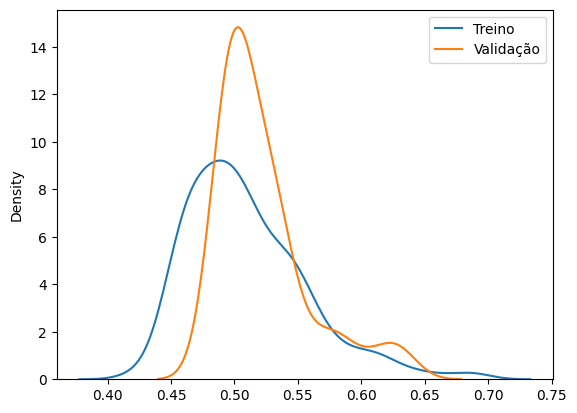

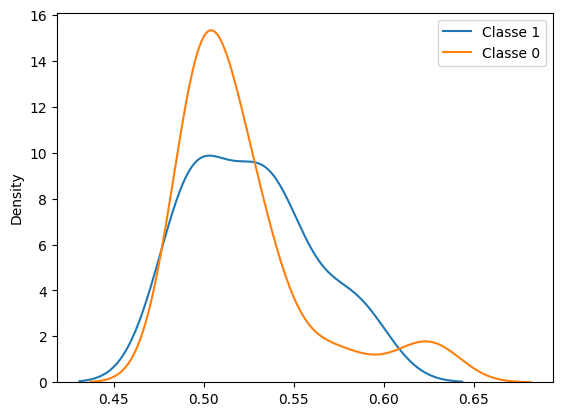

In [16]:
recall_minimo = None
precisao_minima = 0.7
resultado = tr.avaliar_e_logar_modelo(modelo, papel, X_filtrado_train, y_train, X_filtrado_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [21]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 15,
            'max_depth': -1, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': 'balanced'
        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    modelo_final_calibrado = CalibratedClassifierCV(
        modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
        method=metodo_calibracao,
        cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
    )

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado

In [22]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 82, number of negative: 306
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000712 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8591
[LightGBM] [Info] Number of data points in the train set: 388, number of used features: 75
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


AUC no treino: 0.784
AUC na validação: 0.324
Diferença AUC (Treino - Validação): 0.460
PROVÁVEL OVERFITTING
PR AUC no treino: 0.460
PR AUC na validação: 0.355
Diferença PR AUC (Treino - Validação): 0.105


(np.float64(0.7836488983677641),
 np.float64(0.32362873645909834),
 np.float64(0.46002016190866574),
 np.float64(0.45966338331540596),
 np.float64(0.3547523801720737))

Avaliar e logar modelo
MLflow Run ID: ad629103d8c4417e9f52a6622d66b2e5 para ITUB4.SA_15dias_x_0.03val_5dias_alvo
AUC no treino: 0.822
AUC na validação: 0.401

--- Conjunto de Treino --- Janelas


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Threshold 0.50 - AUC: 0.784
  Precisão média (em 370 janelas com previsão positiva): 0.496
  Recall médio: 0.756

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 49.62%
  Recall Médio Esperado: 75.58%
  Janelas Usadas para Precisão: 370.0

Threshold ideal baseado em recall mínimo: 0.50

--- Conjunto de Validação --- Janelas


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Precisão média (em 55 janelas com previsão positiva): 0.273
Recall médio: 0.104
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 11
Modelo ITUB4.SA_15dias_x_0.03val_5dias_alvo salvo na run ad629103d8c4417e9f52a6622d66b2e5


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


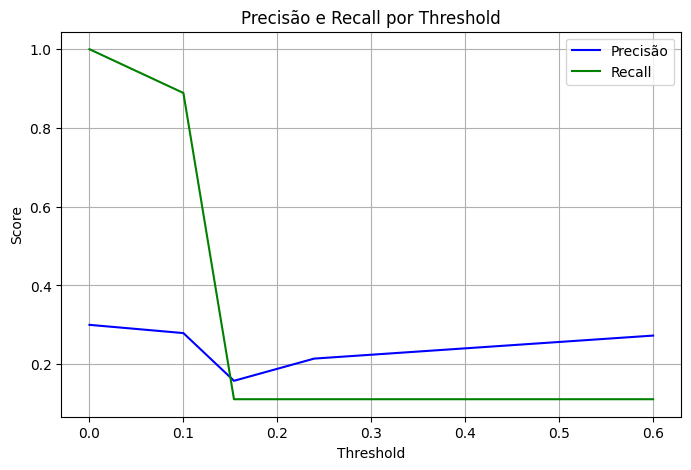

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


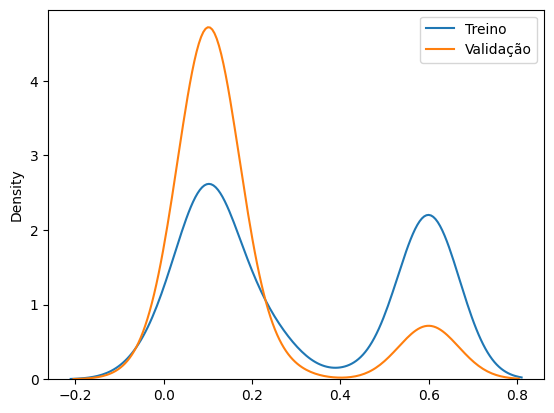

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


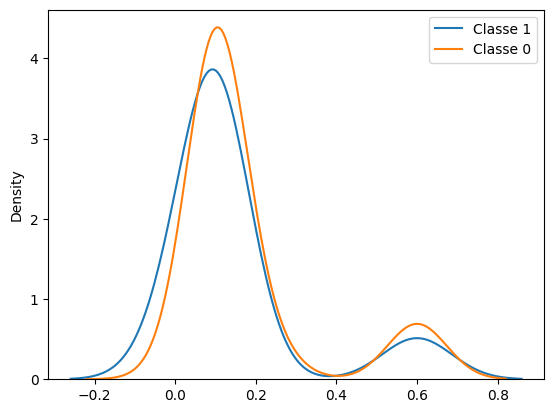

In [23]:
recall_minimo = 0.1  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [ ]:
from sklearn.calibration import CalibratedClassifierCV


calibrated_model = CalibratedClassifierCV(modelo, method='isotonic', cv=5)
calibrated_model.fit(X_train.values, y_train.values)

CalibratedClassifierCV(cv=5,
                       estimator=RandomForestClassifier(class_weight='balanced',
                                                        max_depth=3,
                                                        min_samples_leaf=130,
                                                        n_estimators=200,
                                                        n_jobs=-1,
                                                        random_state=42),
                       method='isotonic')

In [ ]:
recall_minimo = 0.1  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(calibrated_model, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)


Avaliar e logar modelo
MLflow Run ID: df85cc7301c64561adb4cb1b84405962 para ITUB4.SA_60dias_x_0.03val_5dias_alvo
AUC no treino: 0.500
AUC na validação: 0.500

--- Conjunto de Treino --- Janelas


# Redução de features

## Eliminação por correlação

In [ ]:
X_filtrado, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
print("Features removidas por alta correlação:", removidas)

Features removidas por alta correlação: ['atr_pct_mean', 'close_mean', 'retorno_acumulado', 'close_std', 'close_std_norm_atr', 'tr_ultimo_norm_atr', 'ibov_std', 'dias_queda_pct', 'tr_pct_mean', 'close_min', 'close_amplitude']


In [ ]:
modelo_filtrado = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
modelo_filtrado.fit(X_filtrado.values, y_train.values)

LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear')

In [ ]:
coeficientes = pd.Series(modelo_filtrado.coef_[0], index=X_filtrado.columns)
coeficientes = coeficientes.sort_values(ascending=False)

In [ ]:
# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)


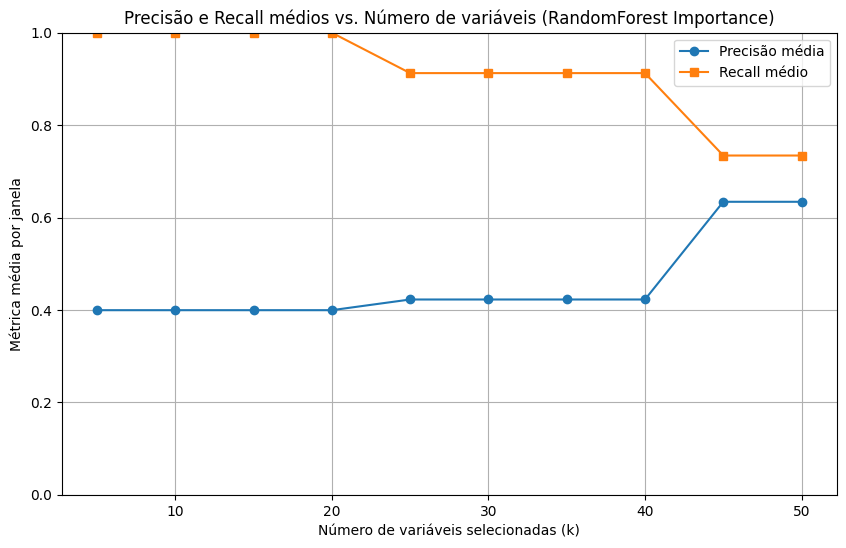

In [ ]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, coeficientes)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas

In [ ]:
n_features = 45
lista_colunas_selecionadas = coeficientes.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_ult_vs_mm_janela',
 'macd_cruzou_sinal_para_cima',
 'rsi_sobrevendido_30',
 'macd_acima_sinal',
 'volume_mean',
 'retorno_medio_neg',
 'retorno_desde_mudanca_ibov',
 'tr_pct_ultimo',
 'atr_pct_ultimo',
 'tr_pct_std',
 'alpha_papel_vs_ibov_mean',
 'retorno_desde_mudanca_close',
 'retorno_mean',
 'retorno_medio_pos',
 'retorno_std',
 'retorno_desde_mudanca_dolar',
 'correl_papel_ibov',
 'dolar_trend',
 'close_trend',
 'volume_ult_vs_mean',
 'volume_trend',
 'volume_std',
 'dolar_std',
 'tr_std',
 'ipca_ultimo',
 'rsi_sobrecomprado_70',
 'tr_ultimo',
 'tr_std_norm_atr',
 'atr_ultimo',
 'tr_mean',
 'atr_mean',
 'beta_papel_ibov',
 'dias_alta_pct',
 'close_dist_min',
 'dolar_ultimo',
 'selic_ultimo',
 'close_amplitude_norm_atr',
 'close_max',
 'rsi_ultimo',
 'rsi_mean',
 'ibov_amplitude',
 'ibov_trend']

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=5,
                                        #min_samples_split=50,
                                        min_samples_leaf=20,                                        
                                        max_features=0.2,
                                        random_state=42,
                                        n_jobs=-1
                                        )

modelo_reduzido = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.614
AUC na validação: 0.809
Diferença AUC (Treino - Validação): -0.194


(np.float64(0.6143047898756531),
 np.float64(0.808655738030058),
 np.float64(-0.1943509481544049))

Avaliar e logar modelo
MLflow Run ID: 4f9785b5b5b848ca8a9449b05a121fdb para ITUB4.SA_15dias_x_0.03val_5dias_alvo
AUC no treino: 0.592
AUC na validação: 0.690

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.614
  Precisão média (em 475 janelas com previsão positiva): 0.266
  Recall médio: 0.637

Threshold Ideal Selecionado: 0.56
  Precisão Média Esperada: 37.79%
  Recall Médio Esperado: 40.37%
  Janelas Usadas para Precisão: 413.0

Threshold ideal baseado em recall mínimo: 0.56

--- Conjunto de Validação --- Janelas
Precisão média (em 52 janelas com previsão positiva): 0.348
Recall médio: 0.384
Sinais de compra presentes na vallidação: 29.0
Sinais de compra previstos na validação: 19
Modelo ITUB4.SA_15dias_x_0.03val_5dias_alvo salvo na run 4f9785b5b5b848ca8a9449b05a121fdb


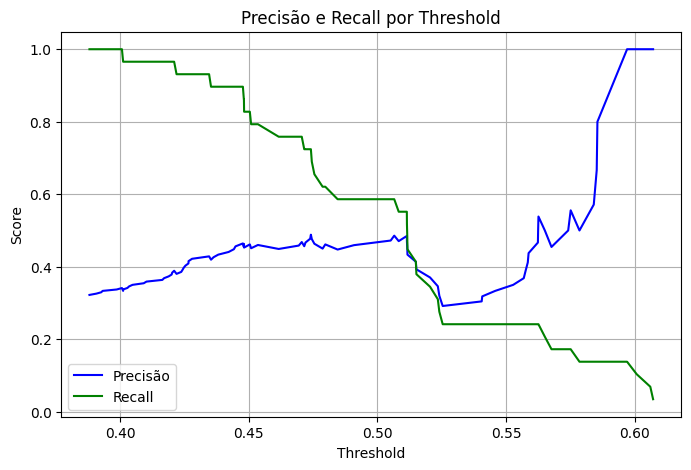

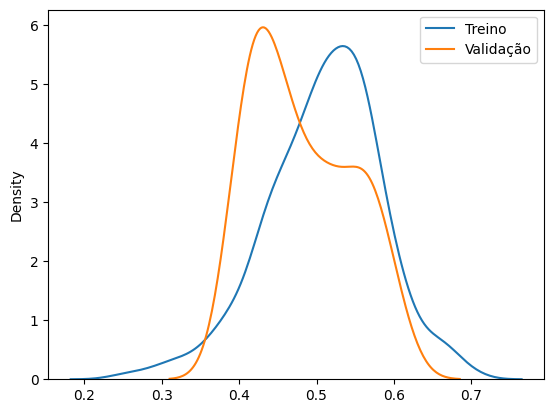

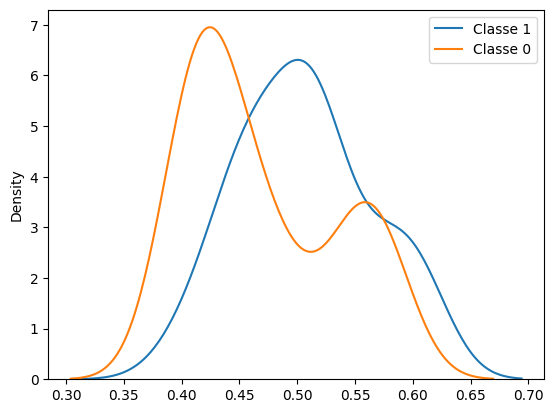

In [29]:
recall_minimo = 0.2
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

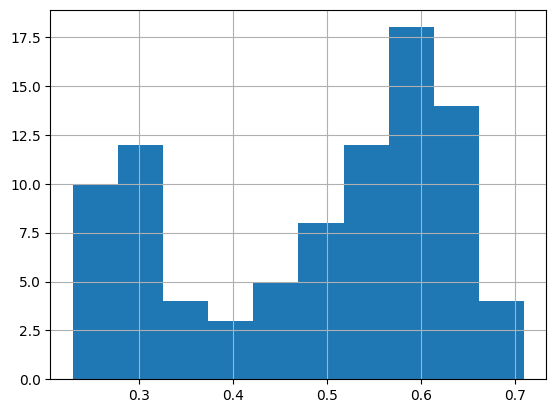

In [24]:
pd.Series(probas).hist()